This Data was collected at Beacon Hill on Sep 3, 2026

The frequencies for the data collection are [30,40,50,60,70,80]kHz

The source is located at H2. The receiver is placed at 2 Locations.

Loc 1: 4m
Loc 2: 8m

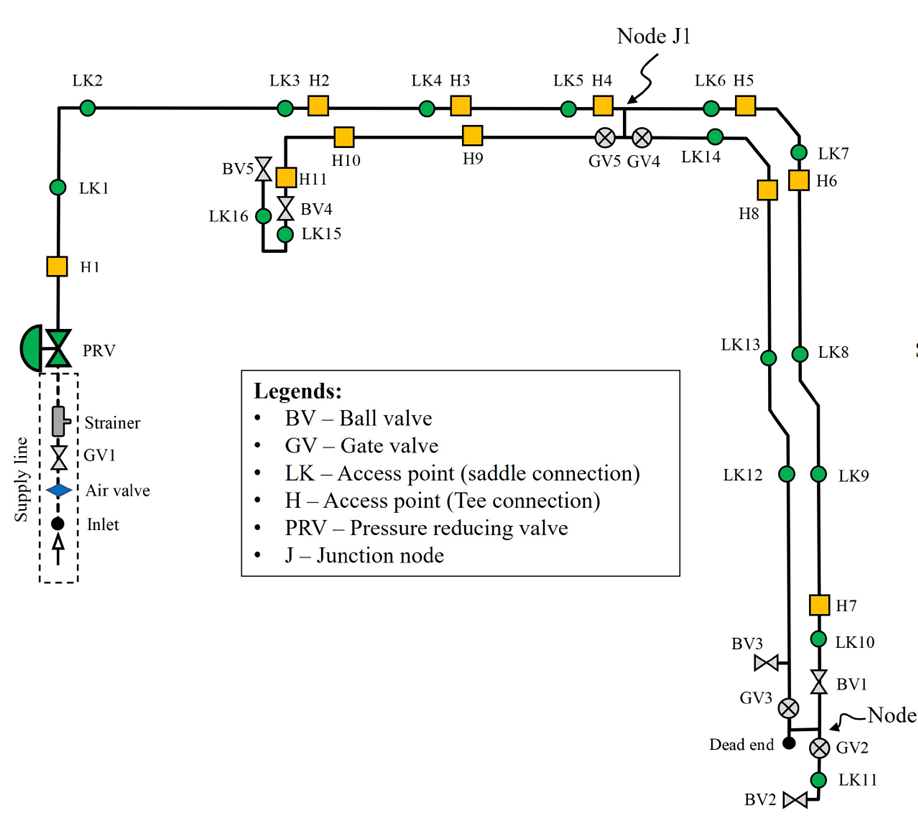


In [59]:
import os
import sys
from scipy.io import loadmat
from scipy.signal import butter, lfilter, sosfilt, sosfreqz, filtfilt
from scipy.fft import fft, ifft
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import h5py


In [60]:
# Loading data from matlab structure files Loc 1 which is 4m away from the source
# The first vector in data file is the common time vector and the next 36 columns are pressure signals


Data_Loc_1 = loadmat(r'C:\Users\Utban\OneDrive - HKUST Connect\PhD\Research\Beacon hill\Sep 3, 2025\LJ tests\Loc_1_new.mat')
Data_Loc_2 = loadmat(r'C:\Users\Utban\OneDrive - HKUST Connect\PhD\Research\Beacon hill\Sep 3, 2025\LJ tests\Loc_2_new.mat')

Data_Loc_1_final = np.vstack([Data_Loc_1['final']])
Data_Loc_2_final = np.vstack([Data_Loc_2['final']])



time_vec = Data_Loc_1_final[:,0]

Pressure_signals_Loc_1 = Data_Loc_1_final[:,1:]

Pressure_signals_Loc_2 = Data_Loc_2_final[:,1:]

The 'pressure_signals' contain 36 pressure signals. The arrangement is as follows:

1) first 12 signals are collected at Re = 0 for Freq = [30,40,50,60,70,80]kHz. Among them the first six are the forward tests, i.e, with the direction of flow (in this case there is no flow but we follow the convention). The next six are then against the flow. For signals 1 and 7 are the signals at 30kHz with and against the flow.
2) From 13:24 are at Re = 20k
3) From 25:36 are at Re = 48k

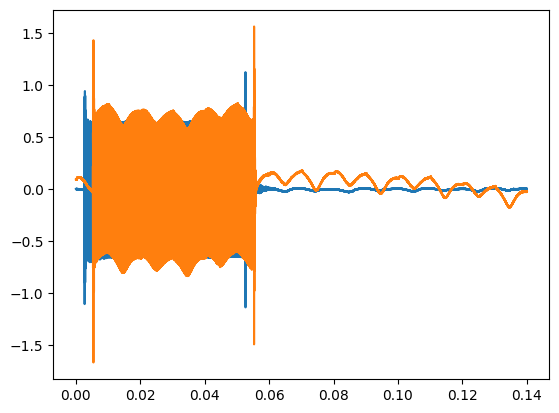

In [61]:
plt.plot(time_vec,Pressure_signals_Loc_1[:,1])
plt.plot(time_vec,Pressure_signals_Loc_2[:,1])



In [63]:
# Applying bandpass filter

def butter_bandpass(lowcut, highcut, fs, order=5):
    """
    Design a Butterworth bandpass filter
    
    Parameters:
    lowcut: Lower cutoff frequency (Hz)
    highcut: Upper cutoff frequency (Hz)
    fs: Sampling frequency (Hz)
    order: Filter order (higher = sharper cutoff)
    """
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    return b, a

def bandpass_filter(data, lowcut, highcut, fs, order=5):
    """
    Apply bandpass filter to data
    
    Parameters:
    data: Input signal array
    lowcut: Lower cutoff frequency (Hz)
    highcut: Upper cutoff frequency (Hz)
    fs: Sampling frequency (Hz)
    order: Filter order
    """
    b, a = butter_bandpass(lowcut, highcut, fs, order=order)
    y = filtfilt(b, a, data)  # Zero-phase filtering
    return y




Lissajous Curves for Loc_1

In [88]:

f_c = 80                            # This is the frequency of the wave
Time_period = 1/f_c                 # Obtain the fundamental period
Fs = 1e6                            # Sampling freq
P = round(2*Time_period*Fs)      # Number of data points in one period

jj = 6                              # Indicator of the frequency vector being analyzed

# D2U = Pressure_signals_Loc_1[:,jj]
# U2D = Pressure_signals_Loc_1[:,jj+6]


# lowcut = 1e4
# highcut = 10e4
# filtered_D2U = bandpass_filter(D2U,lowcut,highcut,Fs)
# filtered_U2D = bandpass_filter(U2D,lowcut,highcut,Fs)


# plt.figure(10)
# plt.plot(time_vec,U2D)
# plt.plot(time_vec,filtered_U2D)



start_point = 18000                 # Starting point for the considered wave period
end_point = start_point+P

# plt.figure(1)
# plt.plot(filtered_D2U[start_point:end_point]/max(filtered_D2U[start_point:end_point]),filtered_U2D[start_point:end_point]/max(filtered_U2D[start_point:end_point]),'k-')
# plt.plot(D2U[start_point:end_point]/max(D2U[start_point:end_point]),U2D[start_point:end_point]/max(U2D[start_point:end_point]),'c--')

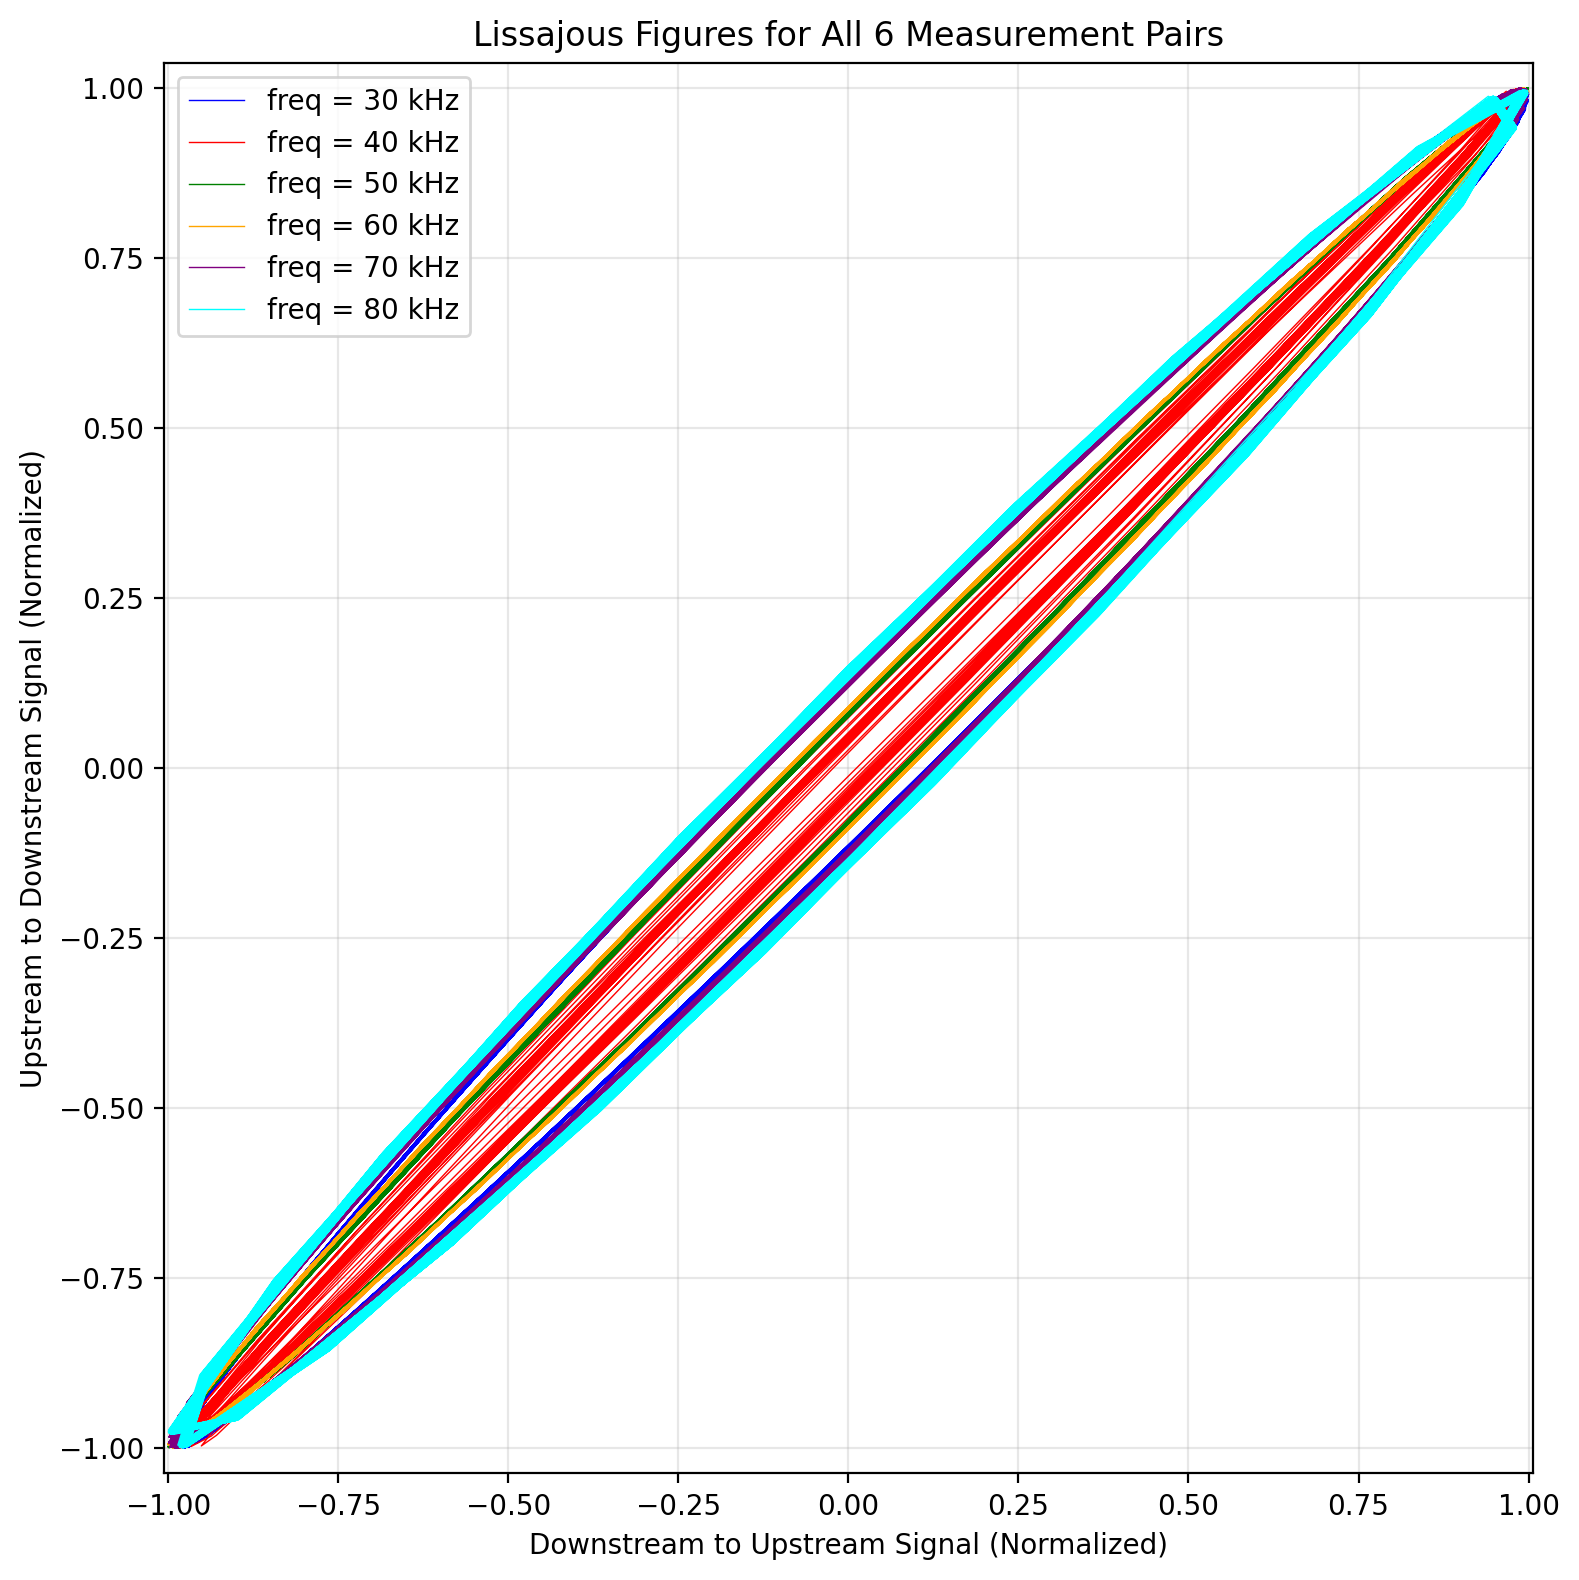

In [117]:

Fs = 1e6
lowcut = 1e4
highcut = 20e4
colors = ['blue', 'red', 'green', 'orange', 'purple', 'cyan']  # 6 distinct colors

plt.rcParams['figure.dpi'] = 200  # High resolution
# plt.rcParams['savefig.dpi'] = 300  # High resolution for saving

fig, ax = plt.subplots(1, 1, figsize=(8, 8))

# Define the frequencies in kHz (assuming 20, 30, 40, 50, 60, 70 kHz)
frequencies_khz = [30, 40, 50, 60, 70, 80]  # Adjust this list if your frequencies are different

for i in range(6):
    D2U = Pressure_signals_Loc_1[:, i]
    U2D = Pressure_signals_Loc_1[:, i+6]
    D2U_filtered = bandpass_filter(D2U,lowcut,highcut,Fs)
    U2D_filtered = bandpass_filter(U2D,lowcut,highcut,Fs)

    # Get the segment of interest
    D2U_segment = D2U_filtered[start_point:end_point]
    U2D_segment = U2D_filtered[start_point:end_point]
    
    # Normalize the segments
    D2U_norm = D2U_segment / np.max(np.abs(D2U_segment))
    U2D_norm = U2D_segment / np.max(np.abs(U2D_segment))
    
    # Plot the Lissajous figure: X = D2U, Y = U2D
    ax.plot(D2U_norm, U2D_norm, color=colors[i], linewidth=0.5, label=f'freq = {frequencies_khz[i]} kHz')

# Add labels, title, grid, and legend
ax.set_xlabel('Downstream to Upstream Signal (Normalized)')
ax.set_ylabel('Upstream to Downstream Signal (Normalized)')
ax.set_title('Lissajous Figures for All 6 Measurement Pairs')
ax.grid(True, alpha=0.3)
ax.legend()

# THIS IS THE MOST IMPORTANT LINE FOR LISSAJOUS FIGURES
ax.axis('equal')  # Critical: ensures 1:1 aspect ratio

# Optional: Set the limits if needed
# ax.set_xlim(-1, 1)
# ax.set_ylim(-1, 1)
plt.xlim(-1, 1)
plt.ylim(-1, 1)
plt.tight_layout()
plt.show()


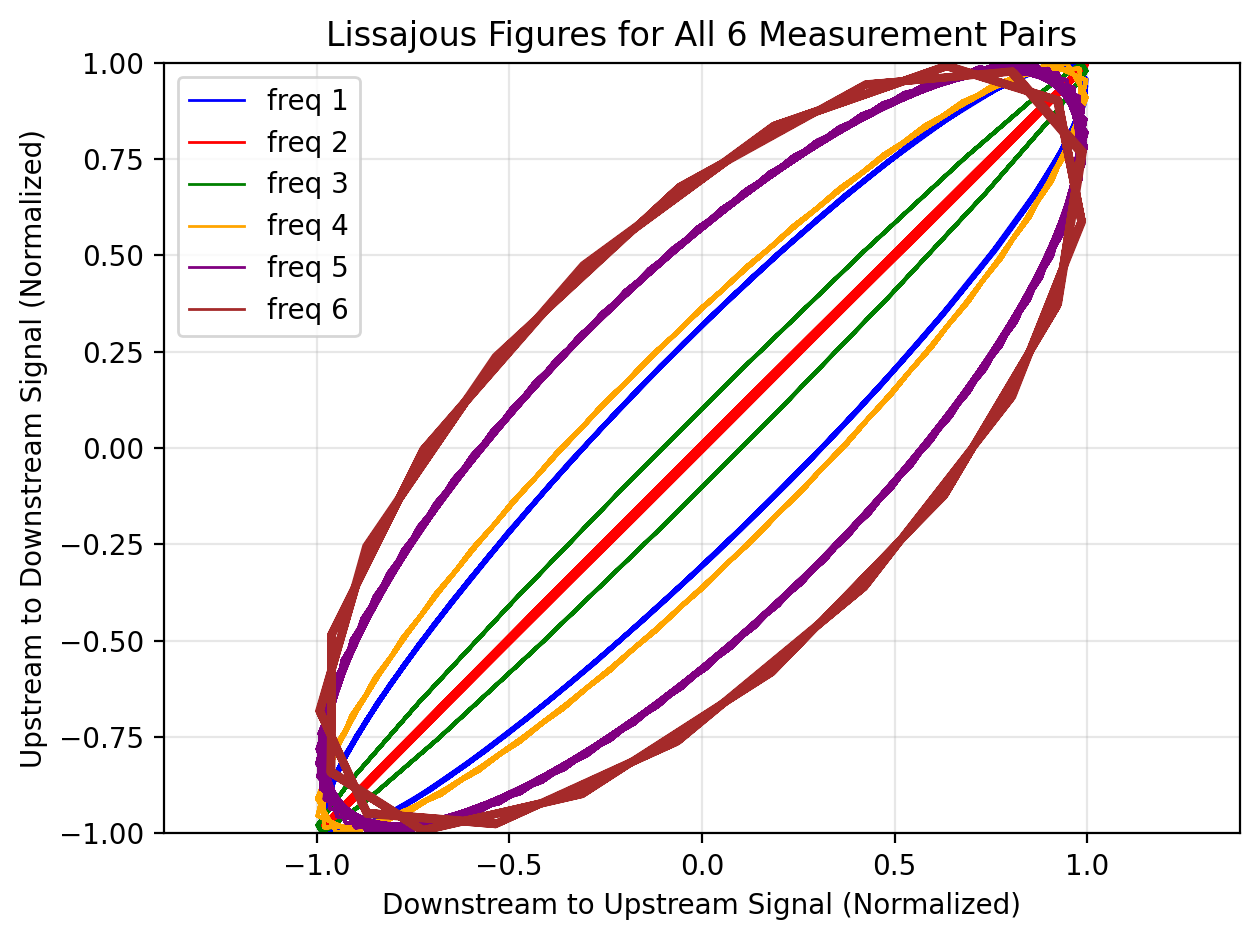

In [114]:

plt.rcParams['figure.dpi'] = 200  # High resolution
# plt.rcParams['savefig.dpi'] = 300  # High resolution for saving

fig, ax = plt.subplots(1)

for i in range(6):
    D2U = Pressure_signals_Loc_1[:, i+12]
    U2D = Pressure_signals_Loc_1[:, i+18]
    D2U_filtered = bandpass_filter(D2U,lowcut,highcut,Fs)
    U2D_filtered = bandpass_filter(U2D,lowcut,highcut,Fs)

    # Get the segment of interest
    D2U_segment = D2U_filtered[start_point:end_point]
    U2D_segment = U2D_filtered[start_point:end_point]
    
    # Normalize the segments
    D2U_norm = D2U_segment / np.max(np.abs(D2U_segment))
    U2D_norm = U2D_segment / np.max(np.abs(U2D_segment))
    
    # Plot the Lissajous figure: X = D2U, Y = U2D
    ax.plot(D2U_norm, U2D_norm, color=colors[i], linewidth=1, label=f'freq {i+1}')

# Add labels, title, grid, and legend
ax.set_xlabel('Downstream to Upstream Signal (Normalized)')
ax.set_ylabel('Upstream to Downstream Signal (Normalized)')
ax.set_title('Lissajous Figures for All 6 Measurement Pairs')
ax.grid(True, alpha=0.3)
ax.legend()

# THIS IS THE MOST IMPORTANT LINE FOR LISSAJOUS FIGURES
ax.axis('equal')  # Critical: ensures 1:1 aspect ratio

# Optional: Set the limits if needed
# ax.set_xlim(-1, 1)
# ax.set_ylim(-1, 1)
plt.xlim(-1, 1)
plt.ylim(-1, 1)
plt.tight_layout()
plt.show()


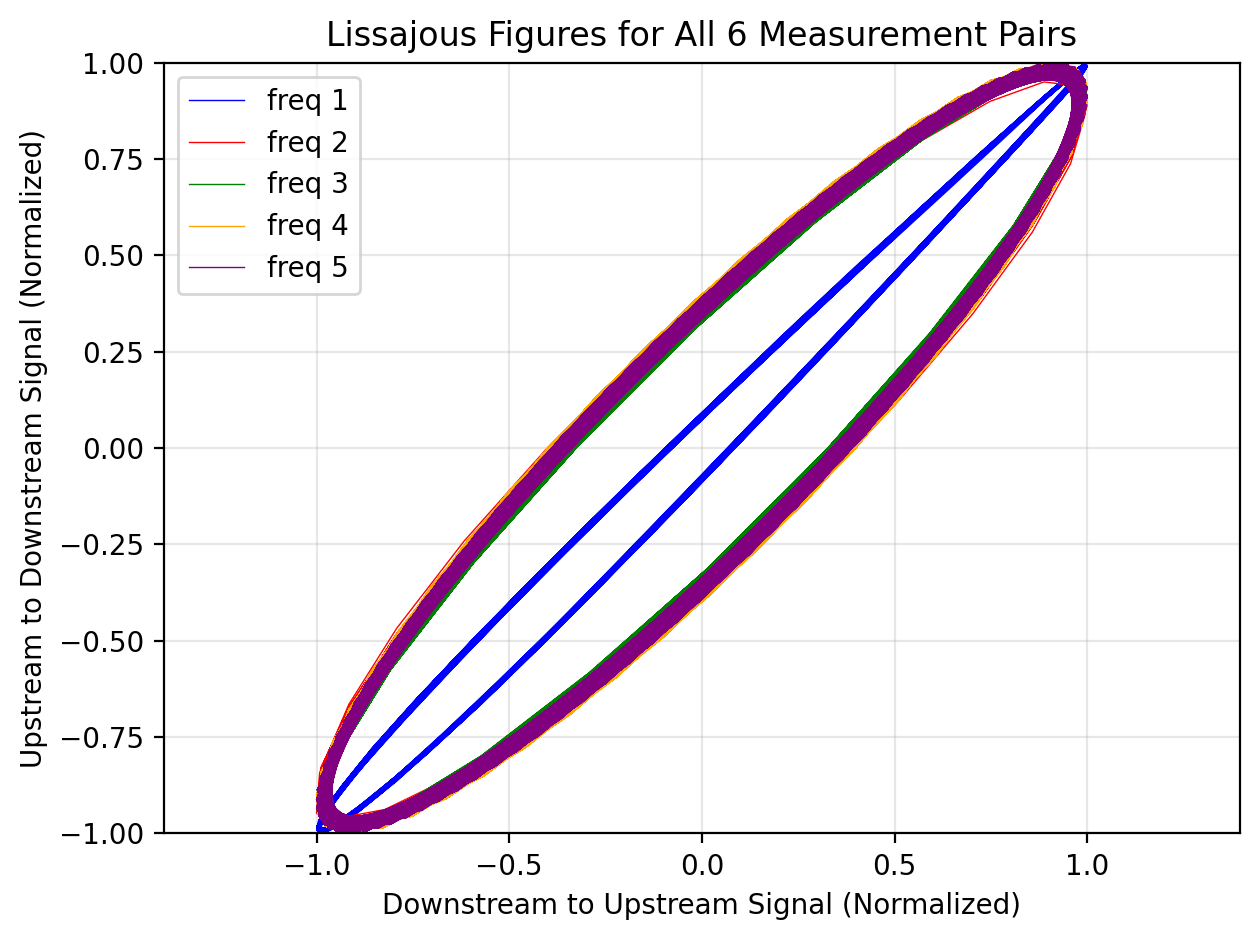

In [112]:
plt.rcParams['figure.dpi'] = 200  # High resolution
# plt.rcParams['savefig.dpi'] = 300  # High resolution for saving

fig, ax = plt.subplots(1)

for i in range(5):
    D2U = Pressure_signals_Loc_1[:, i+24]
    U2D = Pressure_signals_Loc_1[:, i+30]
    D2U_filtered = bandpass_filter(D2U,lowcut,highcut,Fs)
    U2D_filtered = bandpass_filter(U2D,lowcut,highcut,Fs)

    # Get the segment of interest
    D2U_segment = D2U_filtered[start_point:end_point]
    U2D_segment = U2D_filtered[start_point:end_point]
    
    # Normalize the segments
    D2U_norm = D2U_segment / np.max(np.abs(D2U_segment))
    U2D_norm = U2D_segment / np.max(np.abs(U2D_segment))
    
    # Plot the Lissajous figure: X = D2U, Y = U2D
    ax.plot(D2U_norm, U2D_norm, color=colors[i], linewidth=0.5, label=f'freq {i+1}')

# Add labels, title, grid, and legend
ax.set_xlabel('Downstream to Upstream Signal (Normalized)')
ax.set_ylabel('Upstream to Downstream Signal (Normalized)')
ax.set_title('Lissajous Figures for All 6 Measurement Pairs')
ax.grid(True, alpha=0.3)
ax.legend()

# THIS IS THE MOST IMPORTANT LINE FOR LISSAJOUS FIGURES
ax.axis('equal')  # Critical: ensures 1:1 aspect ratio

# Optional: Set the limits if needed
# ax.set_xlim(-1, 1)
# ax.set_ylim(-1, 1)
plt.xlim(-1, 1)
plt.ylim(-1, 1)
plt.tight_layout()
plt.show()
